## Maestría en Inteligencia Artificial Aplicada

### Curso: Inteligencia Artificial y Aprendizaje Automático

**Tecnológico de Monterrey**

Prof. Luis Eduardo Falcón Morales

Actividad de la Semana 8 — Sistemas de Recomendación basados en factorización SVD y Agentes

**Esta actividad se resuelve de manera individual.**

- **Nombre:** Carlos Rodrigo Salguero Alcántara
- **Matrícula:** A00833341


## 1.0 Introduction — movie recommendation with SVD, content and an LLM agent

Se construyen tres versiones de un recomendador de películas sobre **MovieLens 1M** (`ratings.dat`, `users.dat`, `movies.dat`):

1. **Colaborativo (SVD truncado):** factores latentes de las películas a partir de la matriz de utilidad usuario × película.
2. **Híbrido:** los mismos factores latentes más contenido (década, género) y perfil de audiencia (género y edad de quienes la evaluaron).
3. **Agente LLM:** recibe los favoritos del usuario y las candidatas de los dos métodos anteriores, y entrega 5 recomendaciones justificadas.

Dataset: [MovieLens 1M](https://grouplens.org/datasets/movielens/1m/) (GroupLens, 2003). Se usa la copia local en `data/`.

**Modelo LLM utilizado:** `gemma3:4b` (Gemma 3 de Google, 4 mil millones de parámetros), servido localmente con Ollama. Se declara en la constante `LLM_MODEL` (sección 10.4).

**Requisitos:** `pip install numpy pandas scipy scikit-learn matplotlib seaborn`. El agente usa un modelo local servido con [Ollama](https://ollama.com) (`ollama pull gemma3:4b`); no requiere clave de API.


### Roadmap: where each item is answered

| Pregunta / entrega                                         | Sección |
| ---------------------------------------------------------- | ------- |
| 1. Carga, usuarios, películas, evaluaciones y escala       | 3.0     |
| 2. Matriz de utilidad, dispersión e implicaciones          | 4.0     |
| 3. Varianza explicada y número de componentes (80/90/95 %) | 5.0     |
| 4. Partición 80/20, SVD y RMSE vs. número de componentes   | 6.0     |
| 5. Comparación de criterios y selección de `K_LATENT`      | 7.0     |
| 6. Recomendador colaborativo (similitud coseno)            | 8.0     |
| 7. Recomendador híbrido                                    | 9.0     |
| 8. Agente inteligente basado en LLM (incluye el prompt)    | 10.0    |
| 9. Evaluación del agente y comparación de los 3 métodos    | 11.0    |
| 10. Reporte ejecutivo para el CEO                          | 12.0    |
| 11. Comentarios finales                                    | 13.0    |


## 2.0 Notebook setup

Importaciones, constantes del experimento, estilo de gráficos y dataclasses de configuración. La configuración del agente LLM se declara junto al agente, en la sección 10.4.


### 2.1 Imports


In [1]:
from __future__ import annotations

In [2]:
import json
import os
import re
import time
import urllib.request
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Final, Protocol, TypeAlias

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse

In [4]:
from IPython.display import Markdown, display

In [5]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, normalize

### 2.2 Types and experiment constants

Los valores que cambian el experimento (película de consulta, favoritos, perfiles de evaluación, malla de _k_, peso del contenido) viven aquí y no dentro de las funciones. Para reproducir el análisis con otras películas basta con editar esta sección.


In [6]:
ArrayLike: TypeAlias = np.ndarray | pd.Series
SparseMatrix: TypeAlias = sparse.csr_matrix

In [7]:
SEED: Final[int] = 42
RATING_MIN: Final[int] = 1
RATING_MAX: Final[int] = 5
TEST_SIZE: Final[float] = 0.20
N_RECS: Final[int] = 10
N_FINAL: Final[int] = 5

In [8]:
DATA_FILES: Final[tuple[str, ...]] = ("ratings.dat", "users.dat", "movies.dat")
DATA_DIR: Final[Path] = Path("data")

In [9]:
RATINGS_COLUMNS: Final[list[str]] = ["user_id", "movie_id", "rating", "timestamp"]
USERS_COLUMNS: Final[list[str]] = ["user_id", "gender", "age", "occupation", "zip_code"]
MOVIES_COLUMNS: Final[list[str]] = ["movie_id", "title", "genres"]

RATINGS_DTYPES: Final[dict[str, str]] = {
    "user_id": "int32",
    "movie_id": "int32",
    "rating": "int8",
    "timestamp": "int64",
}
USERS_DTYPES: Final[dict[str, str]] = {
    "user_id": "int32",
    "gender": "category",
    "age": "int8",
    "occupation": "int8",
    "zip_code": "str",
}
MOVIES_DTYPES: Final[dict[str, str]] = {
    "movie_id": "int32",
    "title": "str",
    "genres": "str",
}

In [10]:
K_GRID: Final[tuple[int, ...]] = (5, 10, 20, 30, 40, 50, 75, 100, 150, 200)
K_OVERRIDE: Final[int | None] = None  # set a value to bypass the RMSE-based selection
VARIANCE_TARGETS: Final[tuple[float, ...]] = (0.80, 0.90, 0.95)

In [11]:
CONTENT_WEIGHT: Final[float] = 0.30
CONTENT_WEIGHT_GRID: Final[tuple[float, ...]] = (0.0, 0.15, 0.30, 0.50, 0.70)
AUDIENCE_PRIOR: Final[int] = 20

In [12]:
QUERY_TITLE: Final[str] = "Toy Story (1995)"

FAVORITE_TITLES: Final[tuple[str, ...]] = (
    "Matrix, The (1999)",
    "Toy Story (1995)",
    "Godfather, The (1972)",
    "Princess Bride, The (1987)",
    "Fargo (1996)",
)

EVAL_PROFILES: Final[dict[str, tuple[str, ...]]] = {
    "Sci-fi": (
        "Star Wars: Episode IV - A New Hope (1977)",
        "Aliens (1986)",
        "Blade Runner (1982)",
        "Terminator 2: Judgment Day (1991)",
        "Matrix, The (1999)",
    ),
    "Animation & family": (
        "Toy Story (1995)",
        "Lion King, The (1994)",
        "Aladdin (1992)",
        "Bug's Life, A (1998)",
        "Beauty and the Beast (1991)",
    ),
    "Drama & crime": (
        "Godfather, The (1972)",
        "Schindler's List (1993)",
        "Shawshank Redemption, The (1994)",
        "Pulp Fiction (1994)",
        "Usual Suspects, The (1995)",
    ),
}

### 2.3 Plot style and helpers

Paleta y tema comunes para que todas las figuras tengan el mismo formato, más dos auxiliares de gráficos y `rmse()`, que reporta el error en estrellas.


In [13]:
PLOT_PRIMARY: Final[str] = "#2F6F8F"
PLOT_SECONDARY: Final[str] = "#C46B3A"
PLOT_ACCENT: Final[str] = "#3D8B6E"
PLOT_EDGE: Final[str] = "white"
PLOT_PALETTE: Final[list[str]] = [PLOT_PRIMARY, PLOT_SECONDARY, PLOT_ACCENT]

In [14]:
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.float_format", "{:.3f}".format)

In [15]:
def style_axes(
    ax: plt.Axes,
    title: str,
    xlabel: str = "",
    ylabel: str = "",
) -> plt.Axes:
    ax.set_title(title, pad=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    return ax

In [16]:
def finalize_figure() -> None:
    plt.tight_layout()
    plt.show()

In [17]:
def rmse(y_true: ArrayLike, y_pred: ArrayLike) -> float:
    """
    RMSE in rating units (stars, 1-5 scale).
    """

    return float(root_mean_squared_error(y_true, y_pred))

### 2.4 Configuration dataclasses

Agrupan los hiperparámetros de cada etapa (partición, SVD e híbrido) para pasarlos como un solo argumento.


In [18]:
@dataclass(frozen=True, slots=True)
class SplitConfig:
    test_size: float = TEST_SIZE
    random_state: int = SEED

In [19]:
@dataclass(frozen=True, slots=True)
class SvdConfig:
    n_iter: int = 7
    random_state: int = SEED

In [20]:
@dataclass(frozen=True, slots=True)
class HybridConfig:
    content_weight: float = CONTENT_WEIGHT
    audience_prior: int = AUDIENCE_PRIOR

In [21]:
SPLIT_CFG = SplitConfig()
SVD_CFG = SvdConfig()
HYBRID_CFG = HybridConfig()

## 3.0 Exercise 1 — data loading and exploration

Se leen los tres archivos de MovieLens 1M, se valida su integridad y después se responden las preguntas del ejercicio.


### 3.1 Reading the files

Los archivos `.dat` usan `::` como separador y codificación `latin-1` (los títulos tienen acentos). Se fijan tipos explícitos al leerlos para validar el esquema y reducir memoria. `locate_dataset()` verifica que los tres archivos estén en `data/`.


In [22]:
def locate_dataset(folder: Path = DATA_DIR) -> Path:
    """
    Return the folder holding the three local MovieLens files.
    """

    missing = [name for name in DATA_FILES if not (folder / name).exists()]
    if missing:
        raise FileNotFoundError(f"Missing {missing} in {folder.resolve()}/.")

    return folder

In [23]:
@dataclass(frozen=True, slots=True)
class MovieLensData:
    ratings: pd.DataFrame
    users: pd.DataFrame
    movies: pd.DataFrame

In [24]:
def read_dat(path: Path, names: list[str], dtypes: dict[str, str]) -> pd.DataFrame:
    """
    Read a MovieLens ``::``-separated .dat file (latin-1 encoded).
    """

    return pd.read_csv(
        path,
        sep="::",
        engine="python",
        names=names,
        dtype=dtypes,
        encoding="latin-1",
    )

In [25]:
def load_movielens() -> MovieLensData:
    """
    Load ratings, users and movies from the local data folder.
    """

    folder = locate_dataset()
    print(f"Data loaded from: {folder.resolve()}")

    return MovieLensData(
        ratings=read_dat(folder / "ratings.dat", RATINGS_COLUMNS, RATINGS_DTYPES),
        users=read_dat(folder / "users.dat", USERS_COLUMNS, USERS_DTYPES),
        movies=read_dat(folder / "movies.dat", MOVIES_COLUMNS, MOVIES_DTYPES),
    )

In [26]:
ml: MovieLensData = load_movielens()
ratings: pd.DataFrame = ml.ratings
users: pd.DataFrame = ml.users
movies: pd.DataFrame = ml.movies

Data loaded from: C:\Users\carlo\dev\tec\mna\ai_deep_learning\homeworks\movie_recommender\data


### 3.2 Preview and integrity checks

Tamaño en memoria y primeras filas de cada tabla. Las validaciones confirman que no hay valores faltantes, que toda evaluación tiene usuario y película conocidos y que no hay evaluaciones repetidas.


In [27]:
for name, frame in (("ratings", ratings), ("users", users), ("movies", movies)):
    memory_mb = frame.memory_usage(deep=True).sum() / 1_048_576
    print(f"{name}: shape={frame.shape} | memory={memory_mb:.1f} MB")

ratings: shape=(1000209, 4) | memory=16.2 MB
users: shape=(6040, 5) | memory=0.4 MB
movies: shape=(3883, 3) | memory=0.5 MB


In [28]:
display(ratings.head())
display(users.head())
display(movies.head())

,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [29]:
assert ratings.notna().all().all(), "ratings.dat has missing values"
assert ratings["user_id"].isin(users["user_id"]).all(), (
    "ratings from users without demographics"
)
assert ratings["movie_id"].isin(movies["movie_id"]).all(), "movies outside the catalog"
assert not ratings.duplicated(["user_id", "movie_id"]).any(), "duplicate ratings"

### 3.3 Answers (Exercises 1a and 1b)

Número de usuarios, películas y evaluaciones, y escala de calificación con su distribución.


In [30]:
n_users: int = int(ratings["user_id"].nunique())
n_movies_rated: int = int(ratings["movie_id"].nunique())
n_movies_catalog: int = int(movies["movie_id"].nunique())
n_ratings: int = len(ratings)

print(f"Users (with at least one rating): {n_users:,}")
print(f"Rated movies: {n_movies_rated:,}")
print(f"Movies in the catalog (movies.dat): {n_movies_catalog:,}")
print(f"Ratings: {n_ratings:,}")
print(f"Catalog movies without ratings: {n_movies_catalog - n_movies_rated:,}")

Users (with at least one rating): 6,040
Rated movies: 3,706
Movies in the catalog (movies.dat): 3,883
Ratings: 1,000,209
Catalog movies without ratings: 177


In [31]:
rating_values: list[int] = sorted(int(v) for v in ratings["rating"].unique())
rating_counts: pd.Series = ratings["rating"].value_counts().sort_index()

print(f"Rating scale: {rating_values} (whole stars)")
print(f"Mean rating: {ratings['rating'].mean():.3f}")
display(
    pd.DataFrame(
        {
            "ratings": rating_counts,
            "pct": (rating_counts / n_ratings * 100).round(2),
        }
    )
)

Rating scale: [1, 2, 3, 4, 5] (whole stars)
Mean rating: 3.582


,ratings,pct
rating,,
1,56174,5.620
2,107557,10.750
3,261197,26.110
4,348971,34.890
5,226310,22.630


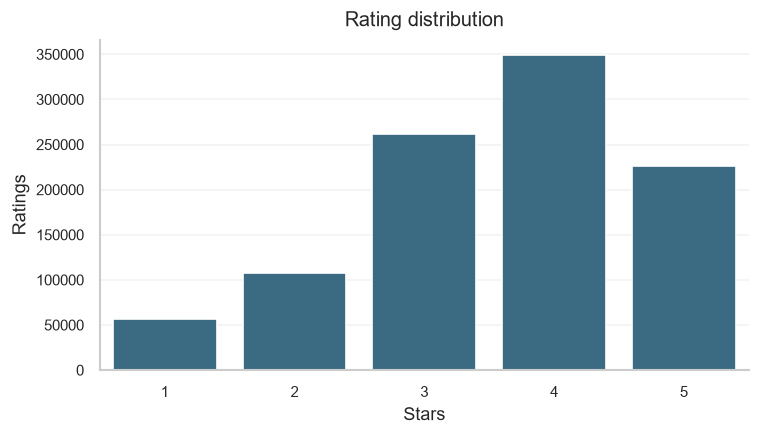

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.barplot(
    x=rating_counts.index,
    y=rating_counts.to_numpy(),
    ax=ax,
    color=PLOT_PRIMARY,
    edgecolor=PLOT_EDGE,
)
style_axes(ax, "Rating distribution", "Stars", "Ratings")
finalize_figure()

## 4.0 Exercise 2 — utility matrix

Se ordenan usuarios y películas por su identificador y se construye la matriz **usuarios × películas** en formato disperso (CSR). Una celda vacía significa "no evaluada" y **no** "calificación cero".


In [33]:
user_index: pd.Index = pd.Index(np.sort(ratings["user_id"].unique()), name="user_id")
movie_index: pd.Index = pd.Index(np.sort(ratings["movie_id"].unique()), name="movie_id")

In [34]:
def to_sparse(frame: pd.DataFrame) -> SparseMatrix:
    """
    Build the users x movies CSR matrix of ratings for the given ratings frame.
    """

    rows = user_index.get_indexer(frame["user_id"])
    cols = movie_index.get_indexer(frame["movie_id"])
    values = frame["rating"].to_numpy(dtype=np.float64)

    return sparse.csr_matrix(
        (values, (rows, cols)),
        shape=(len(user_index), len(movie_index)),
    )

In [35]:
utility: SparseMatrix = to_sparse(ratings)
print(f"Utility matrix shape: {utility.shape}")

Utility matrix shape: (6040, 3706)


### 4.1 Shape, sparsity and memory cost (Exercise 2a)


In [36]:
n_cells: int = utility.shape[0] * utility.shape[1]
density: float = utility.nnz / n_cells
sparsity: float = 1.0 - density

sparse_mb = (
    utility.data.nbytes + utility.indices.nbytes + utility.indptr.nbytes
) / 1_048_576
dense_mb = n_cells * 8 / 1_048_576

print(f"Total cells: {n_cells:,} | rated: {utility.nnz:,}")
print(f"Density: {density:.4%} | sparsity: {sparsity:.4%}")
print(f"CSR memory: {sparse_mb:.1f} MB vs. dense float64: {dense_mb:.1f} MB")

Total cells: 22,384,240 | rated: 1,000,209
Density: 4.4684% | sparsity: 95.5316%
CSR memory: 11.5 MB vs. dense float64: 170.8 MB


In [37]:
ratings_per_user: pd.Series = ratings.groupby("user_id").size()
ratings_per_movie: pd.Series = ratings.groupby("movie_id").size()

display(
    pd.DataFrame(
        {
            "per_user": ratings_per_user.describe(),
            "per_movie": ratings_per_movie.describe(),
        }
    )
)

,per_user,per_movie
count,6040.000,3706.000
mean,165.598,269.889
std,192.747,384.048
min,20.000,1.000
25%,44.000,33.000
50%,96.000,123.500
75%,208.000,350.000
max,2314.000,3428.000


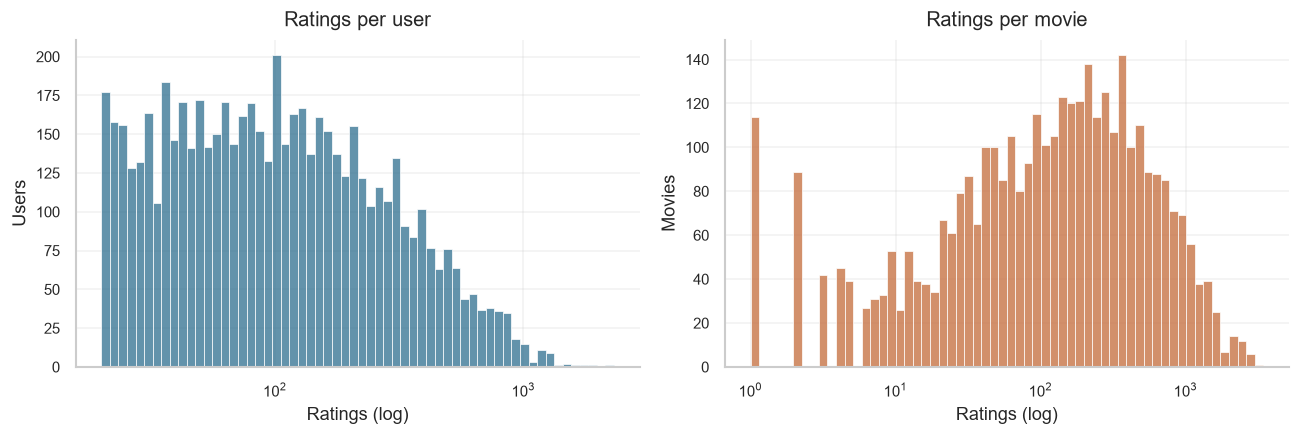

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(
    ratings_per_user, bins=60, log_scale=(True, False), ax=axes[0], color=PLOT_PRIMARY
)
style_axes(axes[0], "Ratings per user", "Ratings (log)", "Users")
sns.histplot(
    ratings_per_movie,
    bins=60,
    log_scale=(True, False),
    ax=axes[1],
    color=PLOT_SECONDARY,
)
style_axes(axes[1], "Ratings per movie", "Ratings (log)", "Movies")
finalize_figure()

### 4.2 Answers (Exercises 2b and 2c)

**2b. ¿Qué dice la dispersión?** Cerca del **95 %** de las celdas está vacío: cada usuario ha visto y calificado una fracción muy pequeña del catálogo. Además, la distribución es de **cola larga**: pocas películas concentran muchas evaluaciones y muchas tienen muy pocas. Las ausencias no son aleatorias (la gente califica lo que decide ver), así que la matriz refleja gustos _y_ exposición. Para películas con pocas evaluaciones hay poca información (arranque en frío).

**2c. Implicaciones computacionales y de modelado:**

- **Memoria:** guardar la matriz densa sería ~170 MB solo para los ceros; el formato disperso (CSR/CSC) guarda únicamente las evaluaciones observadas y permite productos matriz-vector que cuestan O(nnz).
- **Cero ≠ ausencia de gusto:** tratar las celdas vacías como 0 estrellas sesga los factores. Por eso se **centra solo sobre lo observado** (ver 5.0) y se evalúa únicamente sobre pares observados.
- **No densificar:** restar una media global a toda la matriz la volvería densa. `TruncatedSVD` (a diferencia de `PCA`) trabaja sobre matrices dispersas sin centrar columnas.
- **Algoritmos aproximados:** una SVD completa es costosa; se usan métodos truncados/aleatorizados que calculan solo los _k_ componentes principales.
- **Generalización:** con tan pocas observaciones por usuario/película, un _k_ grande sobreajusta; hay que elegir _k_ con una métrica fuera de muestra (6.0).
- **Similitudes:** la matriz de similitud películas × películas sí es densa (n² celdas); hay que vigilar su tamaño si el catálogo crece.


## 5.0 Exercise 3 — explained variance and number of latent components

Primero se centra la matriz por usuario y luego se calcula el espectro completo de valores singulares para leer la varianza acumulada con cualquier _k_.


### 5.1 Per-user centering

Cada usuario califica con su propia vara (unos son estrictos, otros generosos). Se resta a cada evaluación **observada** la media de su usuario; las celdas vacías quedan en 0, que ahora significa "calificación promedio del usuario" y conserva la dispersión.


In [39]:
def center_by_user(
    matrix: SparseMatrix,
    fallback: float,
) -> tuple[SparseMatrix, np.ndarray]:
    """
    Subtract each user's mean from the observed ratings only (sparsity is kept).
    """

    counts = np.diff(matrix.indptr)
    sums = np.asarray(matrix.sum(axis=1)).ravel()
    means = np.full(matrix.shape[0], fallback, dtype=np.float64)
    np.divide(sums, counts, out=means, where=counts > 0)

    centered = matrix.astype(np.float64)
    centered.data = centered.data - np.repeat(means, counts)
    centered.eliminate_zeros()

    return centered, means

In [40]:
GLOBAL_MEAN: float = float(ratings["rating"].mean())
utility_centered, user_means = center_by_user(utility, GLOBAL_MEAN)
print(
    f"Centered matrix: {utility_centered.shape} | non-zeros: {utility_centered.nnz:,}"
)

Centered matrix: (6040, 3706) | non-zeros: 998,088


### 5.2 Singular value spectrum

Se obtiene el espectro completo de valores singulares σ² a partir de la matriz de Gram `XᵀX` (3 706 × 3 706), de modo que la varianza acumulada se puede leer exactamente para cualquier _k_ y no solo hasta el máximo que se ajuste. La varianza acumulada con _k_ componentes es `Σ σᵢ² / Σ σ² totales`.


In [41]:
def variance_spectrum(centered: SparseMatrix) -> np.ndarray:
    """
    Squared singular values (descending) from the Gram matrix X^T X.
    """

    gram = (centered.T @ centered).toarray()
    eigenvalues = np.linalg.eigvalsh(gram)[::-1]

    return np.clip(eigenvalues, 0.0, None)

In [42]:
spectrum: np.ndarray = variance_spectrum(utility_centered)
cumulative_variance: np.ndarray = np.cumsum(spectrum) / spectrum.sum()
print(f"Available components: {len(spectrum):,}")

Available components: 3,706


In [43]:
def components_for(cumulative: np.ndarray, target: float) -> int:
    """
    Smallest number of components whose cumulative variance reaches ``target``.
    """

    return int(np.searchsorted(cumulative, target) + 1)

### 5.3 Cumulative explained variance plot (Exercise 3a)


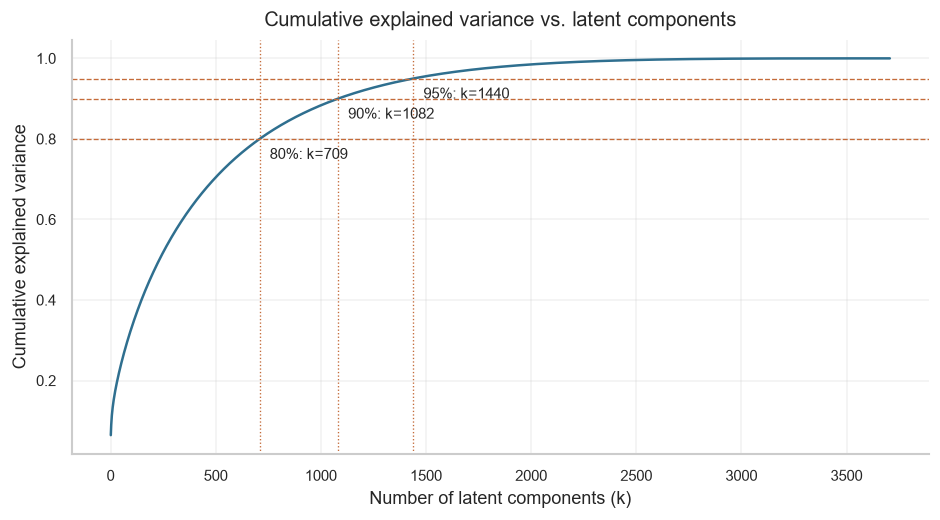

In [44]:
components_by_target: dict[float, int] = {
    target: components_for(cumulative_variance, target) for target in VARIANCE_TARGETS
}

fig, ax = plt.subplots(figsize=(8.0, 4.5))
ax.plot(
    np.arange(1, len(cumulative_variance) + 1), cumulative_variance, color=PLOT_PRIMARY
)
for target, k in components_by_target.items():
    ax.axhline(target, color=PLOT_SECONDARY, linestyle="--", linewidth=0.8)
    ax.axvline(k, color=PLOT_SECONDARY, linestyle=":", linewidth=0.8)
    ax.annotate(
        f"{target:.0%}: k={k}",
        (k, target),
        textcoords="offset points",
        xytext=(6, -12),
        fontsize=9,
    )
style_axes(
    ax,
    "Cumulative explained variance vs. latent components",
    "Number of latent components (k)",
    "Cumulative explained variance",
)
finalize_figure()

### 5.4 Components for 80 %, 90 % and 95 % (Exercise 3b)


In [45]:
variance_table: pd.DataFrame = pd.DataFrame(
    {
        "variance_target": [f"{t:.0%}" for t in components_by_target],
        "components": list(components_by_target.values()),
        "pct_of_total": [
            round(k / len(spectrum) * 100, 1) for k in components_by_target.values()
        ],
    }
)
display(variance_table)

,variance_target,components,pct_of_total
0,80%,709,19.100
1,90%,1082,29.200
2,95%,1440,38.900


In [46]:
for k_ref in (10, 20, 50, 100, 200):
    print(f"k={k_ref:>3}: cumulative variance = {cumulative_variance[k_ref - 1]:.2%}")

k= 10: cumulative variance = 13.37%
k= 20: cumulative variance = 16.87%
k= 50: cumulative variance = 24.11%
k=100: cumulative variance = 33.17%
k=200: cumulative variance = 46.56%


### 5.5 Variance-based selection (Exercise 3c)

**Selección por este criterio: _k_ = 709**, el menor número de componentes que alcanza el 80 % de varianza acumulada. Se elige el 80 % y no el 90 % (1 082) ni el 95 % (1 440) porque la curva no tiene un codo claro: cada punto adicional de varianza cuesta cientos de componentes (pasar de 80 % a 95 % duplica _k_), y con 709 ya se usa el 19 % de todos los componentes posibles.

Este valor debe leerse con cautela. La varianza acumulada **solo mide qué tan bien se reconstruye la matriz centrada** (con los vacíos en 0); no mide qué tan bien se predicen calificaciones nuevas. En una matriz tan dispersa y ruidosa, buena parte de esa varianza es ruido: con _k_ = 20 se explica apenas el 16.9 % y con _k_ = 200 el 46.6 %. Por eso la decisión final se toma en la sección 7.0, contrastando este valor con el RMSE de la sección 6.0.


## 6.0 Exercise 4 — RMSE and number of latent components

La varianza explicada mide reconstrucción; aquí se elige _k_ por su capacidad de predecir evaluaciones que el modelo no vio.


### 6.1 80/20 split

Partición aleatoria **80 % entrenamiento / 20 % prueba** de las _evaluaciones_ (estratificada por usuario, para que todos los usuarios tengan evaluaciones en entrenamiento). La matriz de entrenamiento solo contiene las evaluaciones de entrenamiento; la de prueba nunca se usa para ajustar nada.


In [47]:
train_df, test_df = train_test_split(
    ratings,
    test_size=SPLIT_CFG.test_size,
    random_state=SPLIT_CFG.random_state,
    stratify=ratings["user_id"],
)
print(f"Train: {len(train_df):,} | test: {len(test_df):,}")

Train: 800,167 | test: 200,042


In [48]:
train_matrix: SparseMatrix = to_sparse(train_df)
train_centered, train_means = center_by_user(train_matrix, GLOBAL_MEAN)

train_users = user_index.get_indexer(train_df["user_id"])
train_movies = movie_index.get_indexer(train_df["movie_id"])
test_users = user_index.get_indexer(test_df["user_id"])
test_movies = movie_index.get_indexer(test_df["movie_id"])

y_train = train_df["rating"].to_numpy(dtype=np.float64)
y_test = test_df["rating"].to_numpy(dtype=np.float64)

### 6.2 Truncated SVD fit and prediction

Con `R_centrada ≈ U Σ Vᵀ` truncada a _k_ componentes, la calificación predicha es `media_usuario + (U Σ)ᵤ · Vₘ`, recortada a [1, 5]. Las predicciones se calculan por bloques para no materializar la matriz completa.


In [49]:
@dataclass(frozen=True, slots=True)
class SvdFit:
    k: int
    user_factors: np.ndarray  # U Sigma, shape (n_users, k)
    components: np.ndarray  # V^T, shape (k, n_movies)
    singular_values: np.ndarray
    fit_seconds: float

In [50]:
def fit_svd(centered: SparseMatrix, k: int, cfg: SvdConfig = SVD_CFG) -> SvdFit:
    """
    Fit a randomized truncated SVD with k components on the centered matrix.
    """

    svd = TruncatedSVD(
        n_components=k,
        algorithm="randomized",
        n_iter=cfg.n_iter,
        random_state=cfg.random_state,
    )
    start = time.perf_counter()
    user_factors = svd.fit_transform(centered)
    elapsed = time.perf_counter() - start

    return SvdFit(
        k=k,
        user_factors=user_factors,
        components=svd.components_,
        singular_values=svd.singular_values_,
        fit_seconds=elapsed,
    )

In [51]:
def predict_pairs(
    fit: SvdFit,
    means: np.ndarray,
    user_pos: np.ndarray,
    movie_pos: np.ndarray,
    chunk: int = 50_000,
) -> np.ndarray:
    """
    Predicted ratings for (user, movie) position pairs, clipped to the 1-5 scale.
    """

    predictions = np.empty(len(user_pos), dtype=np.float64)
    for start in range(0, len(user_pos), chunk):
        sl = slice(start, start + chunk)
        latent = fit.user_factors[user_pos[sl]] * fit.components.T[movie_pos[sl]]
        predictions[sl] = latent.sum(axis=1) + means[user_pos[sl]]

    return np.clip(predictions, RATING_MIN, RATING_MAX)

### 6.3 Baseline: user mean

Predecir siempre la media del usuario equivale a _k = 0_; cualquier _k_ útil debe mejorarlo.


In [52]:
baseline_pred = np.clip(train_means[test_users], RATING_MIN, RATING_MAX)
RMSE_BASELINE: float = rmse(y_test, baseline_pred)
print(f"Baseline RMSE (user mean) on test: {RMSE_BASELINE:.4f}")

Baseline RMSE (user mean) on test: 1.0357


### 6.4 RMSE vs. number of components (Exercises 4b and 4c)


In [53]:
rows: list[dict[str, float]] = []
for k in K_GRID:
    fit = fit_svd(train_centered, k)
    rows.append(
        {
            "k": k,
            "rmse_train": rmse(
                y_train, predict_pairs(fit, train_means, train_users, train_movies)
            ),
            "rmse_test": rmse(
                y_test, predict_pairs(fit, train_means, test_users, test_movies)
            ),
            "fit_time_s": fit.fit_seconds,
        }
    )

rmse_results: pd.DataFrame = pd.DataFrame(rows)
display(rmse_results.round({"rmse_train": 4, "rmse_test": 4, "fit_time_s": 2}))

,k,rmse_train,rmse_test,fit_time_s
0,5,0.957,0.974,0.240
1,10,0.939,0.964,0.280
2,20,0.913,0.959,0.360
3,30,0.894,0.961,0.370
4,40,0.876,0.962,0.600
5,50,0.860,0.965,1.300
6,75,0.822,0.970,2.890
7,100,0.788,0.976,4.490
8,150,0.728,0.985,41.080
9,200,0.676,0.993,32.630


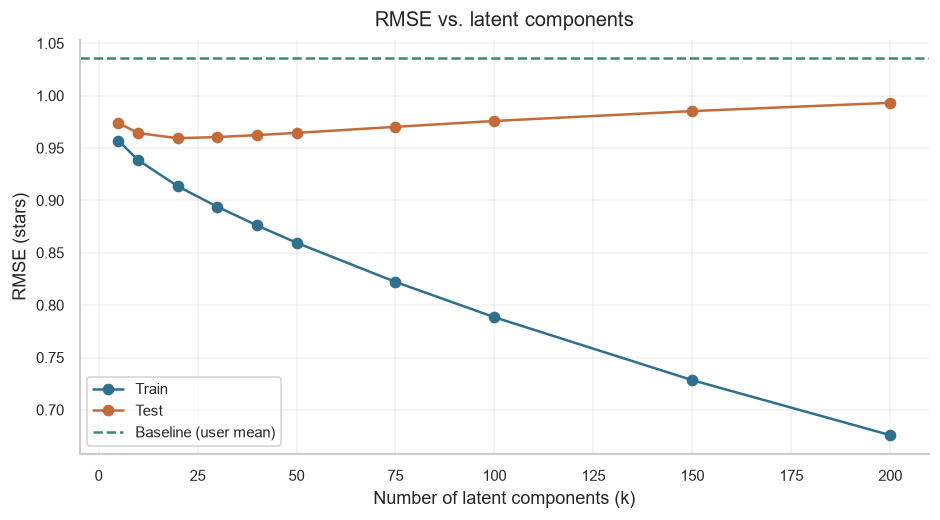

In [54]:
fig, ax = plt.subplots(figsize=(8.0, 4.5))
ax.plot(
    rmse_results["k"],
    rmse_results["rmse_train"],
    marker="o",
    color=PLOT_PRIMARY,
    label="Train",
)
ax.plot(
    rmse_results["k"],
    rmse_results["rmse_test"],
    marker="o",
    color=PLOT_SECONDARY,
    label="Test",
)
ax.axhline(
    RMSE_BASELINE,
    color=PLOT_ACCENT,
    linestyle="--",
    label="Baseline (user mean)",
)
style_axes(
    ax,
    "RMSE vs. latent components",
    "Number of latent components (k)",
    "RMSE (stars)",
)
ax.legend()
finalize_figure()

### 6.5 RMSE-based selection (Exercise 4d)


In [55]:
best_row: pd.Series = rmse_results.loc[rmse_results["rmse_test"].idxmin()]
K_BEST_RMSE: int = int(best_row["k"])
print(
    f"Lowest test RMSE: {best_row['rmse_test']:.4f} at k={K_BEST_RMSE} "
    f"(baseline {RMSE_BASELINE:.4f}, improvement {1 - best_row['rmse_test'] / RMSE_BASELINE:.1%})"
)
print(
    f"Train-test gap at k={K_BEST_RMSE}: "
    f"{best_row['rmse_test'] - best_row['rmse_train']:.4f}"
)

Lowest test RMSE: 0.9594 at k=20 (baseline 1.0357, improvement 7.4%)
Train-test gap at k=20: 0.0459


**Lectura de la curva.** Con pocos componentes el modelo es demasiado simple (_underfitting_: ambos RMSE altos). Al aumentar _k_ el RMSE de entrenamiento baja de forma continua, mientras que el de prueba llega a un mínimo y luego se estanca o sube: el modelo empieza a memorizar las evaluaciones de entrenamiento (_overfitting_). El mínimo de la curva de prueba es el _k_ candidato por RMSE.

**Sesgo de selección.** Como el mismo conjunto de prueba se usa para escoger _k_ y para reportar el RMSE, ese RMSE es ligeramente optimista. Para una estimación imparcial haría falta una tercera partición o validación cruzada.


## 7.0 Exercise 5 — explained variance vs. RMSE

Se ponen lado a lado los dos criterios para cada _k_ de la malla `K_GRID`.


In [56]:
comparison: pd.DataFrame = rmse_results.assign(
    cumulative_variance=[cumulative_variance[k - 1] for k in rmse_results["k"]]
)[["k", "cumulative_variance", "rmse_train", "rmse_test"]]
display(comparison.round(4))

,k,cumulative_variance,rmse_train,rmse_test
0,5,0.107,0.957,0.974
1,10,0.134,0.939,0.964
2,20,0.169,0.913,0.959
3,30,0.196,0.894,0.961
4,40,0.219,0.876,0.962
5,50,0.241,0.860,0.965
6,75,0.289,0.822,0.970
7,100,0.332,0.788,0.976
8,150,0.404,0.728,0.985
9,200,0.466,0.676,0.993


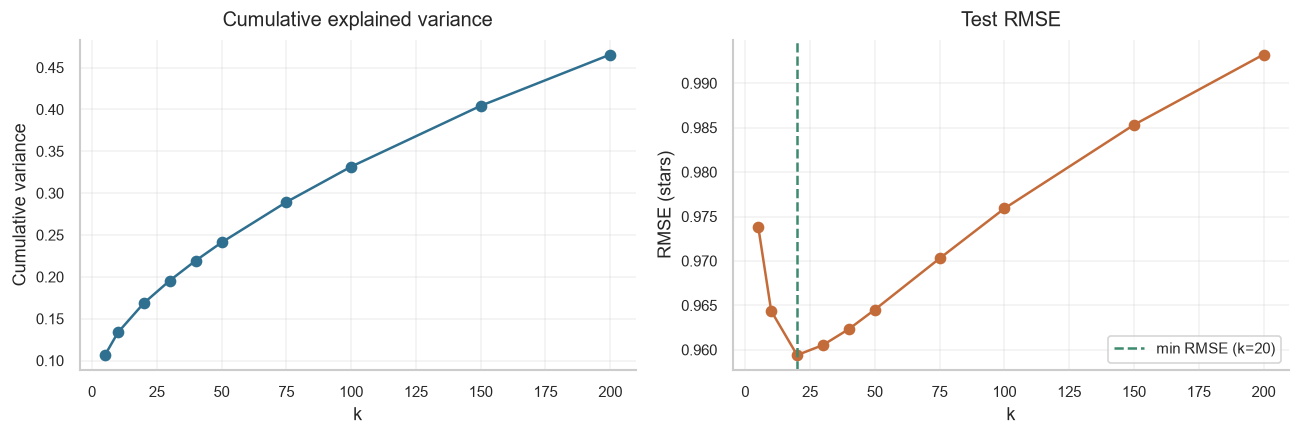

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(
    comparison["k"], comparison["cumulative_variance"], marker="o", color=PLOT_PRIMARY
)
style_axes(axes[0], "Cumulative explained variance", "k", "Cumulative variance")
axes[1].plot(comparison["k"], comparison["rmse_test"], marker="o", color=PLOT_SECONDARY)
axes[1].axvline(
    K_BEST_RMSE,
    color=PLOT_ACCENT,
    linestyle="--",
    label=f"min RMSE (k={K_BEST_RMSE})",
)
style_axes(axes[1], "Test RMSE", "k", "RMSE (stars)")
axes[1].legend()
finalize_figure()

### 7.1 Choosing the number of components

**Criterio adoptado:** el _k_ de menor RMSE en prueba sobre la malla `K_GRID`, porque el objetivo del recomendador es predecir bien lo que el usuario aún no ha visto. La varianza explicada se reporta como referencia, no como criterio de decisión.


In [58]:
K_LATENT: int = K_OVERRIDE if K_OVERRIDE is not None else K_BEST_RMSE
variance_at_k: float = float(cumulative_variance[K_LATENT - 1])

display(
    Markdown(
        f"**Valor seleccionado: `K_LATENT = {K_LATENT}`.** "
        f"Con ese *k* la varianza acumulada es **{variance_at_k:.1%}**, muy por debajo de "
        f"los **{components_by_target[0.80]}** componentes que exigiría el 80 % de varianza. "
        f"A cambio, el RMSE en prueba es **{best_row['rmse_test']:.3f}** frente a "
        f"**{RMSE_BASELINE:.3f}** del baseline."
    )
)

**Valor seleccionado: `K_LATENT = 20`.** Con ese *k* la varianza acumulada es **16.9%**, muy por debajo de los **709** componentes que exigiría el 80 % de varianza. A cambio, el RMSE en prueba es **0.959** frente a **1.036** del baseline.

**¿Por qué los dos criterios no coinciden?** La varianza explicada crece de forma monótona con _k_ y mide ajuste a los datos observados; el RMSE de prueba mide generalización y tiene un mínimo. Los componentes adicionales más allá de ese mínimo capturan idiosincrasias de las evaluaciones de entrenamiento (ruido), no preferencias compartidas. Un _k_ pequeño además da factores de película más compactos y similitudes más estables para el resto de la actividad.


## 8.0 Exercise 6 — collaborative recommender (SVD)

Se reajusta la SVD con `K_LATENT` componentes sobre **todas** las evaluaciones (para recomendar no se necesita reservar datos de prueba). El vector latente de cada película es su columna de `V Σ`: la proyección de sus calificaciones sobre los "gustos" que encontró la SVD. La similitud entre dos películas es el **coseno** de esos vectores.


### 8.1 Catalog and final latent factors

`catalog` alinea `movies.dat` con el orden de columnas de la matriz de utilidad y extrae el año de estreno del título (se usa en el híbrido).


In [59]:
catalog: pd.DataFrame = (
    movies.set_index("movie_id")
    .loc[movie_index]
    .assign(
        year=lambda df: pd.to_numeric(
            df["title"].str.extract(r"\((\d{4})\)\s*$", expand=False),
            errors="coerce",
        )
    )
    .reset_index()
)
assert catalog["year"].notna().all(), "some titles have no release year"
catalog["year"] = catalog["year"].astype(int)
display(catalog.head())

,movie_id,title,genres,year
0,1,Toy Story (1995),Animation|Children's|Comedy,1995
1,2,Jumanji (1995),Adventure|Children's|Fantasy,1995
2,3,Grumpier Old Men (1995),Comedy|Romance,1995
3,4,Waiting to Exhale (1995),Comedy|Drama,1995
4,5,Father of the Bride Part II (1995),Comedy,1995


In [60]:
FINAL_FIT: SvdFit = fit_svd(utility_centered, K_LATENT)
movie_factors: np.ndarray = (FINAL_FIT.components.T * FINAL_FIT.singular_values).astype(
    np.float32
)
print(f"Movie latent factors: {movie_factors.shape}")

Movie latent factors: (3706, 20)


### 8.2 Cosine similarity matrix (Exercises 6a and 6b)


In [61]:
SIM_SVD: np.ndarray = cosine_similarity(movie_factors).astype(np.float32)
print(f"Similarity matrix shape: {SIM_SVD.shape}")
print(f"Memory: {SIM_SVD.nbytes / 1_048_576:.1f} MB (float32)")
print(f"Similarity range: [{SIM_SVD.min():.3f}, {SIM_SVD.max():.3f}]")

Similarity matrix shape: (3706, 3706)
Memory: 52.4 MB (float32)
Similarity range: [-1.000, 1.000]


La matriz es **cuadrada, de 3 706 × 3 706** (una fila y una columna por cada película con al menos una evaluación), simétrica y con 1 en la diagonal.


### 8.3 Recommendation functions

`find_movie()` localiza una película por título y `top_similar()` devuelve las _n_ más parecidas según una matriz de similitud.


In [62]:
def find_movie(query: str) -> int:
    """
    Position of a movie in ``catalog`` by exact title or unique case-insensitive match.
    """

    titles = catalog["title"]
    exact = np.flatnonzero(titles.to_numpy() == query)
    if len(exact) == 1:
        return int(exact[0])

    partial = np.flatnonzero(titles.str.contains(query, case=False, regex=False))
    if len(partial) == 1:
        return int(partial[0])

    options = titles.iloc[partial].head(8).tolist() if len(partial) else []
    raise LookupError(f"'{query}' does not identify a single movie. Options: {options}")

In [63]:
def top_similar(
    similarity: np.ndarray, movie_pos: int, n: int = N_RECS
) -> pd.DataFrame:
    """
    Top-n most similar movies to ``movie_pos`` (itself excluded), descending.
    """

    scores = similarity[movie_pos].astype(np.float64)
    scores[movie_pos] = -np.inf
    top = np.argsort(-scores)[:n]

    return pd.DataFrame(
        {
            "rank": np.arange(1, n + 1),
            "movie_pos": top,
            "title": catalog["title"].to_numpy()[top],
            "genres": catalog["genres"].to_numpy()[top],
            "similarity": scores[top],
        }
    )

### 8.4 Recommendations for the query movie (Exercise 6c)

Película de consulta: la constante `QUERY_TITLE` (sección 2.2).


In [64]:
QUERY_POS: int = find_movie(QUERY_TITLE)
print(f"Query movie: {catalog.loc[QUERY_POS, 'title']}")
print(f"Genres: {catalog.loc[QUERY_POS, 'genres']}")

Query movie: Toy Story (1995)
Genres: Animation|Children's|Comedy


In [65]:
svd_query_recs: pd.DataFrame = top_similar(SIM_SVD, QUERY_POS)
display(svd_query_recs.drop(columns="movie_pos"))

,rank,title,genres,similarity
0,1,Toy Story 2 (1999),Animation|Children's|Comedy,0.949
1,2,"Bug's Life, A (1998)",Animation|Children's|Comedy,0.884
2,3,Aladdin (1992),Animation|Children's|Comedy|Musical,0.831
3,4,Babe (1995),Children's|Comedy|Drama,0.810
4,5,"Iron Giant, The (1999)",Animation|Children's,0.795
5,6,Beauty and the Beast (1991),Animation|Children's|Musical,0.791
6,7,"Lion King, The (1994)",Animation|Children's|Musical,0.745
7,8,Chicken Run (2000),Animation|Children's|Comedy,0.737
8,9,Big (1988),Comedy|Fantasy,0.724
9,10,Back to the Future (1985),Comedy|Sci-Fi,0.721


### 8.5 Are the recommendations coherent? (Exercise 6d)

Sí. Las recomendaciones para _Toy Story (1995)_ son coherentes y en su mayoría esperadas:

- **La secuela aparece primero.** _Toy Story 2 (1999)_ tiene similitud 0.949, muy por encima del resto. Es la prueba de cordura más clara de que los factores latentes capturan algo real.
- **Mismo género y público.** 8 de las 10 son animadas o infantiles (_A Bug's Life_, _Aladdin_, _Babe_, _The Iron Giant_, _Beauty and the Beast_, _The Lion King_, _Chicken Run_), casi todas de los años noventa, como la película de consulta. El SVD no conoce los géneros: los recupera solo a partir de quién calificó qué.
- **No se cuelan películas poco vistas.** La recomendación con menos evaluaciones es _The Iron Giant_, con 674; todas las demás superan las 1 000. Con _k_ = 20 los factores son lo bastante generales para que títulos con pocas evaluaciones no aparezcan por ruido.
- **Las dos sorpresas tienen sentido.** _Big (1988)_ y _Back to the Future (1985)_ no son animadas, pero son comedias familiares de los ochenta que comparten público con _Toy Story_. Muestran que el SVD recomienda por audiencia y no por contenido: sirve para descubrir películas, pero puede parecer arbitrario si se espera solo animación.


### 8.6 Explanation for a non-technical audience (Exercise 6e)

Imagina una tabla gigante donde cada fila es una persona y cada columna una película, y solo unas pocas celdas están llenas con estrellas. El método busca **patrones de gusto ocultos**: por ejemplo, "a quienes les gusta la ciencia ficción clásica tienden a calificar alto estas películas, y a quienes prefieren la comedia romántica, estas otras". Esos patrones no se nombran de antemano; salen de los datos. Cada película queda descrita por **cuánto participa de cada patrón** (unas pocas decenas de números en lugar de miles de calificaciones).

Para recomendar, se buscan las películas cuya "descripción en patrones" es la más parecida a la de la película que te gustó. Es como decir: "a la gente que le gustó esta película también le gustaron aquellas". El sistema no sabe de qué trata la película ni quién la dirigió: **solo sabe cómo la han calificado otras personas**.


## 9.0 Exercise 7 — hybrid recommender

El SVD solo conoce el comportamiento de calificación. Se le añade información **de contenido** (qué es la película) y de **audiencia** (quién la ve) para estabilizar la similitud, sobre todo en películas con pocas evaluaciones.


### 9.1 Release decade (Exercise 7a)

El año de estreno (ej. 1995) tiene demasiados valores distintos y una relación irregular con el gusto; agruparlo en décadas (1990) reduce la cardinalidad y captura "la época" de la película. Después se codifica con _one-hot_.


In [66]:
catalog["decade"] = (catalog["year"] // 10 * 10).astype(int)
decade_counts: pd.Series = catalog["decade"].value_counts().sort_index()
display(decade_counts.to_frame("movies").T)

decade,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000
movies,3,23,72,120,165,187,240,592,2152,152


### 9.2 Selected features (Exercise 7b)

| Factor               | Origen                                | Transformación                                                                   | Motivo                                                                 |
| -------------------- | ------------------------------------- | -------------------------------------------------------------------------------- | ---------------------------------------------------------------------- |
| Década               | `movies.dat` (año en el título)       | año → década → _one-hot_                                                         | Época de la película; baja cardinalidad.                               |
| Género               | `movies.dat` (`Acción\|Comedia\|...`) | _multi-hot_ (18 géneros)                                                         | Es la señal de contenido más directa; una película puede tener varios. |
| Sexo de la audiencia | `users.dat`                           | proporción de mujeres entre quienes la calificaron                               | Resume el público de la película.                                      |
| Edad de la audiencia | `users.dat`                           | edad promedio de quienes la calificaron (el dato ya viene en rangos codificados) | Resume el público de la película.                                      |

**Por qué estos dos de `users.dat`:** sexo y edad son variables de baja cardinalidad con un significado claro para el gusto. Se descartan `zip_code` (miles de valores, casi un identificador) y `occupation` (21 categorías, aportaría muchas columnas con poca señal por película).

**Cómo se pasa de usuario a película.** Los factores de `users.dat` describen personas, pero la matriz híbrida tiene una fila por _película_. Por eso se calcula el perfil de audiencia de cada película. Para que una película con 1 evaluación no quede con un perfil extremo (100 % mujeres, por ejemplo), el promedio se **suaviza hacia el promedio global** con `AUDIENCE_PRIOR` evaluaciones ficticias.

**Ética.** Sexo y edad se usan aquí solo para describir el público _de una película_, no para tratar de forma distinta a un usuario. Aun así, en producción conviene revisar que no refuerce estereotipos.


In [67]:
def audience_profile(
    ratings_frame: pd.DataFrame,
    users_frame: pd.DataFrame,
    prior: int,
) -> pd.DataFrame:
    """
    Per-movie share of female raters and mean age code, shrunk toward the global mean.
    """

    merged = ratings_frame[["user_id", "movie_id"]].merge(
        users_frame[["user_id", "gender", "age"]], on="user_id"
    )
    merged["is_female"] = (merged["gender"] == "F").astype(np.float64)
    merged["age_code"] = merged["age"].astype(np.float64)

    grouped = (
        merged.groupby("movie_id")
        .agg(
            n=("is_female", "size"),
            female_sum=("is_female", "sum"),
            age_sum=("age_code", "sum"),
        )
        .reindex(movie_index)
    )
    n = grouped["n"]

    return pd.DataFrame(
        {
            "share_female": (grouped["female_sum"] + prior * merged["is_female"].mean())
            / (n + prior),
            "mean_age": (grouped["age_sum"] + prior * merged["age_code"].mean())
            / (n + prior),
        },
        index=movie_index,
    )

In [68]:
audience: pd.DataFrame = audience_profile(ratings, users, HYBRID_CFG.audience_prior)
display(audience.describe().T)

,count,mean,std,min,25%,50%,75%,max
share_female,3706.000,0.255,0.088,0.062,0.195,0.241,0.304,0.637
mean_age,3706.000,30.120,3.257,20.193,27.958,29.719,31.893,44.402


### 9.3 Hybrid matrix (Exercise 7c)

Se construyen dos bloques y se pegan columna a columna:

- **Bloque SVD:** `movie_factors` (`K_LATENT` columnas).
- **Bloque de contenido:** géneros (_multi-hot_) + décadas (_one-hot_) + sexo y edad de la audiencia (escalados a [0, 1]).

Cada bloque se normaliza por fila a norma 1 y se pondera con `√(1−w)` (SVD) y `√w` (contenido), con `w = CONTENT_WEIGHT`. Así el híbrido tiene norma 1 y su coseno es exactamente la **mezcla lineal** `(1−w)·coseno_SVD + w·coseno_contenido`: el peso `w` es interpretable.


In [69]:
genre_block: pd.DataFrame = catalog["genres"].str.get_dummies(sep="|")
decade_block: pd.DataFrame = pd.get_dummies(
    catalog["decade"], prefix="decade", dtype=np.float64
)
audience_block: np.ndarray = MinMaxScaler().fit_transform(audience.to_numpy())

content_features: np.ndarray = np.hstack(
    [
        genre_block.to_numpy(dtype=np.float64),
        decade_block.to_numpy(dtype=np.float64),
        audience_block,
    ]
).astype(np.float32)

print(
    f"Content: {genre_block.shape[1]} genres + {decade_block.shape[1]} decades "
    f"+ {audience_block.shape[1]} audience = {content_features.shape[1]} columns"
)

Content: 18 genres + 10 decades + 2 audience = 30 columns


In [70]:
def build_hybrid(
    svd_block: np.ndarray, content_block: np.ndarray, weight: float
) -> np.ndarray:
    """
    Concatenate L2-normalized SVD and content blocks with sqrt weights (unit-norm rows).
    """

    return np.hstack(
        [
            np.sqrt(1.0 - weight) * normalize(svd_block),
            np.sqrt(weight) * normalize(content_block),
        ]
    ).astype(np.float32)

In [71]:
hybrid_matrix: np.ndarray = build_hybrid(
    movie_factors, content_features, HYBRID_CFG.content_weight
)
print(f"Hybrid matrix shape: {hybrid_matrix.shape}")
print(
    f"  = {movie_factors.shape[0]} movies x "
    f"({movie_factors.shape[1]} latent + {content_features.shape[1]} content)"
)

Hybrid matrix shape: (3706, 50)
  = 3706 movies x (20 latent + 30 content)


In [72]:
SIM_HYBRID: np.ndarray = cosine_similarity(hybrid_matrix).astype(np.float32)
SIM_CONTENT: np.ndarray = cosine_similarity(content_features).astype(np.float32)

w = HYBRID_CFG.content_weight
expected = (1 - w) * SIM_SVD[:300, :300] + w * SIM_CONTENT[:300, :300]
assert np.allclose(SIM_HYBRID[:300, :300], expected, atol=1e-4), (
    "linear blend does not hold"
)
print("Verified: hybrid cosine = (1 - w) * SVD cosine + w * content cosine")

Verified: hybrid cosine = (1 - w) * SVD cosine + w * content cosine


### 9.4 Benefits of the augmented matrix (Exercise 7d)

- **Arranque en frío:** una película con pocas evaluaciones tiene factores SVD ruidosos; el contenido (género, época) ancla su similitud a algo estable.
- **Coherencia temática:** evita recomendaciones "por accidente" entre películas de géneros muy distintos que solo comparten audiencia.
- **Mayor control:** el peso `w` permite ajustar cuánto pesa el comportamiento frente al contenido sin reentrenar la SVD.
- **Mejor explicabilidad:** parte de la similitud puede explicarse con atributos legibles (género, década), no solo con factores latentes.
- **Costos:** más columnas por mantener, decisiones de ingeniería de variables (qué incluir, cómo escalar) y riesgo de sobrerrepresentar atributos de contenido si `w` es muy alto.


### 9.5 SVD vs. hybrid for the same movie (Exercise 7e)


In [73]:
hybrid_query_recs: pd.DataFrame = top_similar(SIM_HYBRID, QUERY_POS)

comparison_query: pd.DataFrame = pd.DataFrame(
    {
        "rank": svd_query_recs["rank"],
        "SVD": svd_query_recs["title"],
        "sim_svd": svd_query_recs["similarity"],
        "Hybrid": hybrid_query_recs["title"],
        "sim_hybrid": hybrid_query_recs["similarity"],
    }
)
display(comparison_query)

shared = set(svd_query_recs["movie_pos"]) & set(hybrid_query_recs["movie_pos"])
print(f"Shared recommendations (out of {N_RECS}): {len(shared)}")

,rank,SVD,sim_svd,Hybrid,sim_hybrid
0,1,Toy Story 2 (1999),0.949,Toy Story 2 (1999),0.964
1,2,"Bug's Life, A (1998)",0.884,"Bug's Life, A (1998)",0.919
2,3,Aladdin (1992),0.831,Aladdin (1992),0.851
3,4,Babe (1995),0.810,"Iron Giant, The (1999)",0.819
4,5,"Iron Giant, The (1999)",0.795,Babe (1995),0.797
5,6,Beauty and the Beast (1991),0.791,Beauty and the Beast (1991),0.783
6,7,"Lion King, The (1994)",0.745,"Wrong Trousers, The (1993)",0.755
7,8,Chicken Run (2000),0.737,"Grand Day Out, A (1992)",0.752
8,9,Big (1988),0.724,"Lion King, The (1994)",0.751
9,10,Back to the Future (1985),0.721,Chicken Run (2000),0.745


Shared recommendations (out of 10): 8


### 9.6 Sensitivity to the content weight

Con `w = 0` el híbrido es el SVD puro; al subir `w` el contenido gana peso.


In [74]:
sensitivity_rows: list[dict[str, float]] = []
svd_top_set = set(top_similar(SIM_SVD, QUERY_POS)["movie_pos"])
for weight in CONTENT_WEIGHT_GRID:
    hybrid_w = build_hybrid(movie_factors, content_features, weight)
    sim_row = hybrid_w @ hybrid_w[QUERY_POS]
    sim_row[QUERY_POS] = -np.inf
    top_set = set(np.argsort(-sim_row)[:N_RECS])
    sensitivity_rows.append(
        {"content_w": weight, "shared_with_svd": len(top_set & svd_top_set)}
    )

display(pd.DataFrame(sensitivity_rows))

,content_w,shared_with_svd
0,0.000,10
1,0.150,8
2,0.300,8
3,0.500,6
4,0.700,5


### 9.7 Comments on both methods (Exercise 7f)

- **Coinciden 8 de 10.** Los dos métodos comparten las tres primeras (_Toy Story 2_, _A Bug's Life_, _Aladdin_) casi en el mismo orden. El híbrido sube un poco la similitud de las primeras (0.964 vs. 0.949 para _Toy Story 2_) porque, además del comportamiento, coinciden en género y década.
- **Lo que cambia es el final de la lista.** El híbrido saca _Big_ y _Back to the Future_ (comedias de los ochenta sin animación) y mete _The Wrong Trousers (1993)_ y _A Grand Day Out (1992)_, cortos animados de Wallace & Gromit de los noventa. Las 10 recomendaciones del híbrido son animadas o infantiles: el contenido hace la lista más coherente en género y época.
- **El costo es menos sorpresa.** Las dos películas que salen eran justo las recomendaciones "por público" que el SVD sí capturaba. El híbrido es más predecible y, por lo mismo, descubre menos.
- **Ayuda a títulos con menos datos.** Las dos películas nuevas tienen menos evaluaciones (882 y 473) que las que reemplazan (1 491 y 2 583), lo que concuerda con la idea de que el contenido da estabilidad donde la señal colaborativa es más débil.
- **Peso del contenido.** En la tabla de sensibilidad, con _w_ = 0.15 y 0.30 se conservan 8 de las 10 del SVD; con 0.50 bajan a 6 y con 0.70 a 5. _w_ = 0.30 parece razonable: el contenido corrige el final de la lista sin reemplazar la señal colaborativa, que es la que más información aporta.


## 10.0 Exercise 8 — recommendation with an intelligent agent

**Arquitectura.** El agente **no** busca en el catálogo por su cuenta: recibe los favoritos del usuario y una lista **cerrada** de candidatas generadas por SVD e híbrido, con sus puntajes, y solo puede elegir entre ellas y justificar. Esto mantiene el cálculo de similitud fuera del LLM y reduce el riesgo de alucinaciones; además, cada respuesta se **valida en código** (ver 10.6).

```
favoritos ─► SVD (top 10) ─┐
                           ├─► candidatas (unión) ─► LLM ─► 5 recomendaciones + justificación ─► validación
favoritos ─► híbrido (top 10) ┘
```


### 10.1 User profile: 10 recommendations per method (Exercise 8a)

El perfil de un usuario con varios favoritos se resume con el **promedio de las similitudes** de cada candidata con cada favorita (los favoritos se excluyen).


In [75]:
def resolve_titles(titles: tuple[str, ...] | list[str]) -> np.ndarray:
    """
    Catalog positions for a list of movie titles.
    """

    return np.array([find_movie(title) for title in titles], dtype=np.int64)

In [76]:
def recommend_for_profile(
    similarity: np.ndarray,
    fav_pos: np.ndarray,
    n: int = N_RECS,
) -> pd.DataFrame:
    """
    Top-n movies by mean similarity to the favorites, with the closest favorite.
    """

    scores = similarity[fav_pos].mean(axis=0).astype(np.float64)
    scores[fav_pos] = -np.inf
    top = np.argsort(-scores)[:n]
    closest = fav_pos[np.argmax(similarity[fav_pos][:, top], axis=0)]

    return pd.DataFrame(
        {
            "rank": np.arange(1, n + 1),
            "movie_pos": top,
            "title": catalog["title"].to_numpy()[top],
            "genres": catalog["genres"].to_numpy()[top],
            "similarity": scores[top],
            "closest_favorite": catalog["title"].to_numpy()[closest],
        }
    )

In [77]:
FAV_POS: np.ndarray = resolve_titles(FAVORITE_TITLES)
display(catalog.loc[FAV_POS, ["title", "genres"]].reset_index(drop=True))

,title,genres
0,"Matrix, The (1999)",Action|Sci-Fi|Thriller
1,Toy Story (1995),Animation|Children's|Comedy
2,"Godfather, The (1972)",Action|Crime|Drama
3,"Princess Bride, The (1987)",Action|Adventure|Comedy|Romance
4,Fargo (1996),Crime|Drama|Thriller


In [78]:
start = time.perf_counter()
svd_recs: pd.DataFrame = recommend_for_profile(SIM_SVD, FAV_POS)
svd_seconds: float = time.perf_counter() - start

start = time.perf_counter()
hybrid_recs: pd.DataFrame = recommend_for_profile(SIM_HYBRID, FAV_POS)
hybrid_seconds: float = time.perf_counter() - start

In [79]:
profile_comparison: pd.DataFrame = pd.DataFrame(
    {
        "rank": svd_recs["rank"],
        "SVD": svd_recs["title"],
        "sim_svd": svd_recs["similarity"],
        "Hybrid": hybrid_recs["title"],
        "sim_hybrid": hybrid_recs["similarity"],
    }
)
display(profile_comparison)

,rank,SVD,sim_svd,Hybrid,sim_hybrid
0,1,"Usual Suspects, The (1995)",0.672,"Usual Suspects, The (1995)",0.602
1,2,Raiders of the Lost Ark (1981),0.669,"Silence of the Lambs, The (1991)",0.566
2,3,L.A. Confidential (1997),0.648,Raiders of the Lost Ark (1981),0.563
3,4,"Shawshank Redemption, The (1994)",0.629,"Shawshank Redemption, The (1994)",0.561
4,5,Monty Python and the Holy Grail (1974),0.627,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.559
5,6,"Silence of the Lambs, The (1991)",0.618,L.A. Confidential (1997),0.559
6,7,"Sixth Sense, The (1999)",0.612,"Sixth Sense, The (1999)",0.549
7,8,Star Wars: Episode IV - A New Hope (1977),0.610,Pulp Fiction (1994),0.546
8,9,"Christmas Story, A (1983)",0.601,"Close Shave, A (1995)",0.544
9,10,"Professional, The (a.k.a. Leon: The Professional) (1994)",0.601,Life Is Beautiful (La Vita è bella) (1997),0.540


### 10.2 Candidates for the agent

La lista de candidatas es la **unión** de ambos top 10. Para cada una se reportan sus dos puntajes (SVD e híbrido) aunque solo haya aparecido en uno de los dos rankings.


In [80]:
def build_candidates(
    svd_top: pd.DataFrame,
    hybrid_top: pd.DataFrame,
    fav_pos: np.ndarray,
) -> pd.DataFrame:
    """
    Union of both top lists with both similarity scores and the list of origin.
    """

    positions = np.unique(
        np.concatenate([svd_top["movie_pos"], hybrid_top["movie_pos"]])
    )
    in_svd = np.isin(positions, svd_top["movie_pos"])
    in_hybrid = np.isin(positions, hybrid_top["movie_pos"])

    frame = pd.DataFrame(
        {
            "movie_pos": positions,
            "title": catalog["title"].to_numpy()[positions],
            "genres": catalog["genres"].to_numpy()[positions],
            "score_svd": SIM_SVD[fav_pos][:, positions].mean(axis=0),
            "score_hybrid": SIM_HYBRID[fav_pos][:, positions].mean(axis=0),
            "source": np.select(
                [in_svd & in_hybrid, in_svd],
                ["both", "SVD only"],
                default="hybrid only",
            ),
        }
    )
    frame["score_mean"] = frame[["score_svd", "score_hybrid"]].mean(axis=1)

    return frame.sort_values("score_mean", ascending=False).reset_index(drop=True)

In [81]:
candidates: pd.DataFrame = build_candidates(svd_recs, hybrid_recs, FAV_POS)
print(
    f"Candidates: {len(candidates)} (in both rankings: {(candidates['source'] == 'both').sum()})"
)
display(candidates.drop(columns=["movie_pos", "score_mean"]))

Candidates: 13 (in both rankings: 7)


,title,genres,score_svd,score_hybrid,source
0,"Usual Suspects, The (1995)",Crime|Thriller,0.672,0.602,both
1,Raiders of the Lost Ark (1981),Action|Adventure,0.669,0.563,both
2,L.A. Confidential (1997),Crime|Film-Noir|Mystery|Thriller,0.648,0.559,both
3,"Shawshank Redemption, The (1994)",Drama,0.629,0.561,both
4,"Silence of the Lambs, The (1991)",Drama|Thriller,0.618,0.566,both
5,"Sixth Sense, The (1999)",Thriller,0.612,0.549,both
6,"Professional, The (a.k.a. Leon: The Professional) (1994)",Crime|Drama|Romance|Thriller,0.601,0.559,both
7,Monty Python and the Holy Grail (1974),Comedy,0.627,0.517,SVD only
8,Pulp Fiction (1994),Crime|Drama,0.592,0.546,hybrid only
9,"Close Shave, A (1995)",Animation|Comedy|Thriller,0.594,0.544,hybrid only


### 10.3 Agent prompt (Exercise 8d)

El prompt se compone de un mensaje de **sistema** (rol, reglas y formato de salida) y un mensaje de **usuario** (favoritos y candidatas). Las reglas atacan directamente los riesgos de un LLM: solo candidatas, títulos exactos, justificaciones basadas en la evidencia entregada y salida en JSON verificable.


In [82]:
SYSTEM_PROMPT: Final[str] = f"""\
Eres un agente recomendador de películas. Recibirás las películas favoritas de un \
usuario y una lista CERRADA de películas candidatas, cada una con sus géneros y dos \
puntajes de similitud (svd y híbrido, entre -1 y 1; mayor es más parecido a los \
favoritos del usuario).

Tu tarea: elegir las {N_FINAL} mejores recomendaciones finales para este usuario.

Reglas obligatorias:
1. Elige EXACTAMENTE {N_FINAL} películas y SOLO de la lista de candidatas.
2. Copia el título tal cual aparece en la lista (incluye el año). No traduzcas \
ni corrijas títulos.
3. No repitas películas ni recomiendes las favoritas del usuario.
4. Justifica cada elección en 1 o 2 oraciones, en español, usando únicamente la \
evidencia dada: géneros, año, puntajes de similitud, origen (SVD only / hybrid only / both) \
y su relación con los favoritos. No inventes director, reparto, trama, premios ni \
datos que no aparezcan en la entrada.
5. Busca equilibrio: prioriza puntajes altos, pero evita que las {N_FINAL} sean \
casi idénticas entre sí (diversidad de géneros o épocas cuando los puntajes sean \
parecidos).
6. Responde SOLO con un objeto JSON válido, sin texto adicional ni bloques de código, \
con este formato:

{{
  "recommendations": [
    {{"title": "<título exacto de la lista>", "reason": "<justificación>"}}
  ]
}}
"""

In [83]:
USER_PROMPT_TEMPLATE: Final[str] = """\
## Películas favoritas del usuario
{favorites_block}

## Películas candidatas (únicas elegibles)
formato: título | géneros | svd=<puntaje> | hibrido=<puntaje> | origen=<ranking donde aparece>
{candidates_block}

Elige las {n_final} mejores recomendaciones finales siguiendo las reglas del sistema.
"""

In [84]:
def build_user_prompt(fav_pos: np.ndarray, candidate_frame: pd.DataFrame) -> str:
    """
    Fill the user prompt template with the favorites and the candidate list.
    """

    favorites_block = "\n".join(
        f"- {catalog.loc[pos, 'title']} | {catalog.loc[pos, 'genres']}"
        for pos in fav_pos
    )
    candidates_block = "\n".join(
        f"- {row.title} | {row.genres} | svd={row.score_svd:.3f} | "
        f"hibrido={row.score_hybrid:.3f} | origen={row.source}"
        for row in candidate_frame.itertuples()
    )

    return USER_PROMPT_TEMPLATE.format(
        favorites_block=favorites_block,
        candidates_block=candidates_block,
        n_final=N_FINAL,
    )

In [85]:
user_prompt: str = build_user_prompt(FAV_POS, candidates)
print("=== SYSTEM MESSAGE ===")
print(SYSTEM_PROMPT)
print("=== USER MESSAGE ===")
print(user_prompt)

=== SYSTEM MESSAGE ===
Eres un agente recomendador de películas. Recibirás las películas favoritas de un usuario y una lista CERRADA de películas candidatas, cada una con sus géneros y dos puntajes de similitud (svd y híbrido, entre -1 y 1; mayor es más parecido a los favoritos del usuario).

Tu tarea: elegir las 5 mejores recomendaciones finales para este usuario.

Reglas obligatorias:
1. Elige EXACTAMENTE 5 películas y SOLO de la lista de candidatas.
2. Copia el título tal cual aparece en la lista (incluye el año). No traduzcas ni corrijas títulos.
3. No repitas películas ni recomiendes las favoritas del usuario.
4. Justifica cada elección en 1 o 2 oraciones, en español, usando únicamente la evidencia dada: géneros, año, puntajes de similitud, origen (SVD only / hybrid only / both) y su relación con los favoritos. No inventes director, reparto, trama, premios ni datos que no aparezcan en la entrada.
5. Busca equilibrio: prioriza puntajes altos, pero evita que las 5 sean casi idéntica

### 10.4 LLM configuration and client

`LLM_MODEL` es el modelo que elige y justifica las recomendaciones finales; la celda que crea el cliente lo imprime para dejar constancia del modelo usado. `LLM_TEMPERATURE = 0.0` hace que las elecciones sean reproducibles, `LLM_CONTEXT_WINDOW` asegura que el prompt completo quepa en el contexto del modelo y `LLM_MAX_ATTEMPTS` limita los reintentos cuando la respuesta no es un JSON válido.

El agente depende de un protocolo mínimo `LLMClient` (`complete(system, user)`), de modo que se puede cambiar de proveedor sin tocar el resto del código. La implementación incluida usa un modelo local servido con Ollama (`/api/chat`), así que no hay costo por llamada ni datos que salgan de la máquina.

`AGENT_RESPONSE_SCHEMA` se envía como `format` para que Ollama obligue al modelo a devolver exactamente `N_FINAL` objetos `{title, reason}`. Con el modo JSON genérico, un modelo pequeño puede responder `{}`. El esquema solo fija la _forma_: los títulos siguen siendo texto libre, así que la validación de 10.6 sigue midiendo si el modelo se sale de la lista o inventa títulos.


In [86]:
LLM_MODEL: Final[str] = "gemma3:4b"
LLM_MAX_TOKENS: Final[int] = 2000
LLM_TEMPERATURE: Final[float | None] = 0.0  # None uses the model default
LLM_MAX_ATTEMPTS: Final[int] = 2
LLM_CONTEXT_WINDOW: Final[int] = 8192
LLM_TIMEOUT_S: Final[int] = 300  # the first call also loads the model
OLLAMA_HOST: Final[str] = "http://localhost:11434"

In [87]:
@dataclass(frozen=True, slots=True)
class AgentConfig:
    model: str = LLM_MODEL
    max_tokens: int = LLM_MAX_TOKENS
    temperature: float | None = LLM_TEMPERATURE
    max_attempts: int = LLM_MAX_ATTEMPTS
    context_window: int = LLM_CONTEXT_WINDOW
    timeout_s: int = LLM_TIMEOUT_S
    host: str = OLLAMA_HOST

In [88]:
AGENT_CFG = AgentConfig()

In [89]:
@dataclass(frozen=True, slots=True)
class LLMResponse:
    text: str
    input_tokens: int
    output_tokens: int
    latency_s: float

In [90]:
class LLMClient(Protocol):
    def complete(self, system: str, user: str) -> LLMResponse: ...

In [91]:
def check_ollama(cfg: AgentConfig = AGENT_CFG) -> None:
    """
    Fail early if the Ollama server is down or the model has not been pulled.
    """

    try:
        with urllib.request.urlopen(f"{cfg.host}/api/tags", timeout=5) as response:
            models = {m["name"] for m in json.loads(response.read())["models"]}
    except OSError as error:
        raise RuntimeError(
            f"Ollama is not reachable at {cfg.host}. Start it with: ollama serve"
        ) from error

    if cfg.model not in models:
        raise RuntimeError(f"Model not found. Pull it with: ollama pull {cfg.model}")

In [92]:
AGENT_RESPONSE_SCHEMA: Final[dict[str, object]] = {
    "type": "object",
    "properties": {
        "recommendations": {
            "type": "array",
            "minItems": N_FINAL,
            "maxItems": N_FINAL,
            "items": {
                "type": "object",
                "properties": {
                    "title": {"type": "string"},
                    "reason": {"type": "string"},
                },
                "required": ["title", "reason"],
            },
        }
    },
    "required": ["recommendations"],
}

In [93]:
class OllamaClient:
    """
    Minimal LLMClient backed by a local Ollama server (/api/chat).
    """

    def __init__(
        self,
        cfg: AgentConfig = AGENT_CFG,
        response_schema: dict[str, object] = AGENT_RESPONSE_SCHEMA,
    ) -> None:
        check_ollama(cfg)
        self._cfg = cfg
        self._schema = response_schema

    def complete(self, system: str, user: str) -> LLMResponse:
        options: dict[str, object] = {
            "num_predict": self._cfg.max_tokens,
            "num_ctx": self._cfg.context_window,
        }
        if self._cfg.temperature is not None:
            options["temperature"] = self._cfg.temperature

        payload = {
            "model": self._cfg.model,
            "messages": [
                {"role": "system", "content": system},
                {"role": "user", "content": user},
            ],
            "format": self._schema,
            "stream": False,
            "options": options,
        }
        request = urllib.request.Request(
            f"{self._cfg.host}/api/chat",
            data=json.dumps(payload).encode("utf-8"),
            headers={"Content-Type": "application/json"},
        )

        start = time.perf_counter()
        with urllib.request.urlopen(request, timeout=self._cfg.timeout_s) as response:
            body = json.loads(response.read())
        latency = time.perf_counter() - start

        return LLMResponse(
            text=body["message"]["content"],
            input_tokens=int(body.get("prompt_eval_count", 0)),
            output_tokens=int(body.get("eval_count", 0)),
            latency_s=latency,
        )

In [94]:
LLM_CLIENT: LLMClient = OllamaClient()
print(f"LLM model used: {AGENT_CFG.model}")

LLM model used: gemma3:4b


### 10.5 Running the agent (Exercises 8b and 8c)

`run_agent()` envía el prompt, interpreta el JSON y reintenta solo si la respuesta no se puede leer o no trae `N_FINAL` películas. Se registran tokens y latencia de cada llamada para el análisis de costo (Ejercicio 9).


In [95]:
def parse_agent_json(text: str) -> list[dict[str, str]]:
    """
    Parse the agent's JSON answer into a list of {title, reason} dicts.
    """

    cleaned = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    payload = json.loads(cleaned[cleaned.find("{") : cleaned.rfind("}") + 1])
    items = payload["recommendations"]

    return [
        {"title": str(item["title"]).strip(), "reason": str(item["reason"]).strip()}
        for item in items
    ]

In [96]:
@dataclass(frozen=True, slots=True)
class AgentResult:
    picks: pd.DataFrame
    raw_text: str
    attempts: int
    input_tokens: int
    output_tokens: int
    latency_s: float

In [97]:
def run_agent(
    client: LLMClient,
    fav_pos: np.ndarray,
    candidate_frame: pd.DataFrame,
    cfg: AgentConfig = AGENT_CFG,
) -> AgentResult:
    """
    Ask the LLM for the final picks; retry only when the JSON is malformed.
    """

    user_message = build_user_prompt(fav_pos, candidate_frame)
    tokens_in = tokens_out = 0
    latency = 0.0
    last_error: Exception | None = None

    for attempt in range(1, cfg.max_attempts + 1):
        response = client.complete(SYSTEM_PROMPT, user_message)
        tokens_in += response.input_tokens
        tokens_out += response.output_tokens
        latency += response.latency_s
        try:
            picks = parse_agent_json(response.text)
        except (ValueError, KeyError, TypeError) as error:
            last_error = error
            continue

        if len(picks) == N_FINAL:
            return AgentResult(
                picks=pd.DataFrame(picks),
                raw_text=response.text,
                attempts=attempt,
                input_tokens=tokens_in,
                output_tokens=tokens_out,
                latency_s=latency,
            )
        last_error = ValueError(f"expected {N_FINAL} movies, got {len(picks)}")

    raise RuntimeError(f"The agent did not return valid JSON: {last_error}")

In [98]:
agent_result: AgentResult = run_agent(LLM_CLIENT, FAV_POS, candidates)
print(
    f"Attempts: {agent_result.attempts} | tokens: {agent_result.input_tokens} "
    f"in / {agent_result.output_tokens} out | latency: {agent_result.latency_s:.1f} s"
)
for i, row in enumerate(agent_result.picks.itertuples(), start=1):
    print(f"{i}. {row.title}\n   {row.reason}\n")

Attempts: 1 | tokens: 1057 in / 401 out | latency: 15.1 s
1. The Usual Suspects, The (1995)
   Tiene un puntaje de similitud alto (0.672) tanto en SVD como en híbrido, y comparte el género de Crimen con 'The Godfather', lo que sugiere una afinidad por thrillers y dramas criminales.

2. Raiders of the Lost Ark (1981)
   El puntaje de similitud de 0.669 en SVD y 0.563 en híbrido lo posiciona como una opción sólida, y comparte el género de Acción y Aventura con 'Matrix' y 'Princess Bride', ofreciendo una experiencia similar.

3. L.A. Confidential (1997)
   Con un puntaje de 0.648 en SVD y 0.559 en híbrido, se alinea con el gusto por el crimen y el thriller, similar a 'Fargo', y el género Film-Noir añade un elemento distintivo.

4. The Shawshank Redemption, The (1994)
   El puntaje de similitud de 0.629 en SVD y 0.561 en híbrido lo hace una recomendación atractiva, compartiendo el género Drama con las favoritas del usuario, y ofreciendo una narrativa emocionalmente resonante.

5. Sixth Sen

### 10.6 Hallucination checks

El agente puede fallar de tres formas distintas, y cada una se detecta en código:

- **Fuera de candidatas:** el título existe en el catálogo pero no estaba en la lista entregada (viola la regla 1).
- **Inventada:** el título no existe en `movies.dat` (alucinación dura).
- **Favorita repetida:** recomienda algo que el usuario ya declaró como favorito (viola la regla 3).

Además se mide la **coherencia de géneros** (índice de Jaccard entre los géneros de las recomendadas y los de los favoritos) como señal objetiva de que la recomendación se parece al perfil.


In [99]:
def evaluate_picks(
    picks: pd.DataFrame,
    candidate_frame: pd.DataFrame,
    fav_pos: np.ndarray,
) -> dict[str, float]:
    """
    Count title-level failures and genre coherence of the agent picks.
    """

    candidate_titles = set(candidate_frame["title"])
    catalog_titles = set(catalog["title"])
    favorite_titles = set(catalog["title"].to_numpy()[fav_pos])

    titles = picks["title"].tolist()
    outside = [t for t in titles if t in catalog_titles and t not in candidate_titles]
    invented = [t for t in titles if t not in catalog_titles]
    repeated = [t for t in titles if t in favorite_titles]

    favorite_genres = set("|".join(catalog["genres"].to_numpy()[fav_pos]).split("|"))
    jaccards = []
    for title in titles:
        if title in catalog_titles:
            genres = set(
                catalog.loc[catalog["title"] == title, "genres"].iloc[0].split("|")
            )
            jaccards.append(
                len(genres & favorite_genres) / len(genres | favorite_genres)
            )

    return {
        "valid": len(titles) - len(outside) - len(invented) - len(repeated),
        "outside_candidates": len(outside),
        "invented": len(invented),
        "repeated_favorite": len(repeated),
        "genre_jaccard": float(np.mean(jaccards)) if jaccards else 0.0,
    }

In [100]:
agent_eval: dict[str, float] = evaluate_picks(agent_result.picks, candidates, FAV_POS)
display(pd.DataFrame([agent_eval], index=["agent"]))

,valid,outside_candidates,invented,repeated_favorite,genre_jaccard
agent,3,0,2,0,0.156


## 11.0 Exercise 9 — agent evaluation

Se ejecuta el mismo agente con **tres perfiles de usuario** de características distintas (`EVAL_PROFILES`, sección 2.2): ciencia ficción, animación y familia, y drama y crimen. Cada perfil tiene 5 películas favoritas. `run_profile()` repite el flujo completo de la sección 10 para cada uno. Así se cumple y amplía el requisito de evaluar con al menos 3 películas diferentes: cada perfil representa un tipo de usuario distinto.


In [101]:
def run_profile(name: str, titles: tuple[str, ...]) -> dict[str, object]:
    """
    Full pipeline for one profile: SVD + hybrid candidates, agent, validation.
    """

    fav_pos = resolve_titles(titles)

    start = time.perf_counter()
    svd_top = recommend_for_profile(SIM_SVD, fav_pos)
    hybrid_top = recommend_for_profile(SIM_HYBRID, fav_pos)
    classic_seconds = time.perf_counter() - start

    candidate_frame = build_candidates(svd_top, hybrid_top, fav_pos)
    result = run_agent(LLM_CLIENT, fav_pos, candidate_frame)
    metrics = evaluate_picks(result.picks, candidate_frame, fav_pos)

    return {
        "profile": name,
        "fav_pos": fav_pos,
        "svd_top": svd_top,
        "hybrid_top": hybrid_top,
        "candidates": candidate_frame,
        "result": result,
        "metrics": metrics,
        "classic_seconds": classic_seconds,
    }

In [102]:
profile_runs: list[dict[str, object]] = [
    run_profile(name, titles) for name, titles in EVAL_PROFILES.items()
]

### 11.1 Results summary (Exercise 9a)


In [103]:
for run in profile_runs:
    result: AgentResult = run["result"]
    print(f"=== Profile: {run['profile']} ===")
    print("Favorites:", " | ".join(catalog["title"].to_numpy()[run["fav_pos"]]))
    for i, row in enumerate(result.picks.itertuples(), start=1):
        print(f"{i}. {row.title}\n   {row.reason}")
    print()

=== Profile: Sci-fi ===
Favorites: Star Wars: Episode IV - A New Hope (1977) | Aliens (1986) | Blade Runner (1982) | Terminator 2: Judgment Day (1991) | Matrix, The (1999)
1. Terminator, The (1984)
   El puntaje de similitud SVD es alto (0.809), y la película comparte géneros como Acción y Sci-Fi con las favoritas del usuario, especialmente Terminator 2: Judgment Day. Además, el puntaje híbrido es considerable, lo que indica una buena coincidencia con el gusto del usuario.
2. Alien (1979)
   Este título tiene un alto puntaje de similitud tanto en SVD (0.746) como en híbrido (0.696), y comparte géneros como Acción, Sci-Fi y Thriller con las películas favoritas del usuario, como Aliens. Su origen en ambos rankings refuerza su potencial de recomendación.
3. Star Wars: Episode V - The Empire Strikes Back (1980)
   El puntaje SVD (0.710) es alto, y la película comparte géneros clave como Acción, Adventure, Sci-Fi y War con las favoritas del usuario.  El puntaje híbrido también es significat

In [104]:
evaluation_summary: pd.DataFrame = pd.DataFrame(
    [
        {
            "profile": run["profile"],
            **run["metrics"],
            "attempts": run["result"].attempts,
            "input_tokens": run["result"].input_tokens,
            "output_tokens": run["result"].output_tokens,
            "latency_s": run["result"].latency_s,
        }
        for run in profile_runs
    ]
).set_index("profile")
display(evaluation_summary)

,valid,outside_candidates,invented,repeated_favorite,genre_jaccard,attempts,input_tokens,output_tokens,latency_s
profile,,,,,,,,,
Sci-fi,5,0,0,0,0.375,1,1038,440,8.702
Animation & family,5,0,0,0,0.660,1,988,409,8.204
Drama & crime,5,0,0,0,0.377,1,926,391,7.918


### 11.2 Coherence and hallucinations (Exercise 9b)

**Fallos verificables.** En los tres perfiles, las 15 recomendaciones son válidas: ninguna fuera de candidatas, inventada ni repetida. En cambio, en la corrida del Ejercicio 8 (sección 10.6) el agente reescribió dos títulos: devolvió _"The Usual Suspects, The (1995)"_ y _"The Shawshank Redemption, The (1994)"_, anteponiendo "The" a títulos que ya lo llevan al final, pese a la regla 2 (copiar el título tal cual). Las películas sí estaban en la lista, pero esos títulos no existen en el catálogo, así que en un sistema real no se podrían enlazar. Es una alucinación de forma más que de contenido, y la validación en código la detectó (2 inventadas de 5).

**Coherencia por perfil.**

- _Sci-fi:_ coherente (_The Terminator_, _Alien_, _Raiders of the Lost Ark_, _Die Hard_, _Star Trek II_). El agente omitió _The Empire Strikes Back_, la tercera candidata por puntaje, sin explicar por qué.
- _Animación y familia:_ totalmente coherente (_Mulan_, _Toy Story 2_, _The Little Mermaid_, _Tarzan_, _Fantasia 2000_) y el perfil más alineado en géneros (Jaccard 0.66, frente a ~0.36–0.38 de los otros dos).
- _Drama y crimen:_ coherente (_The Silence of the Lambs_, _GoodFellas_, _L.A. Confidential_, _Fargo_, _One Flew Over the Cuckoo's Nest_). Evitó _Sling Blade_ y _Some Folks Call It a Sling Blade_ (el cortometraje original de la misma historia), en línea con la regla de diversidad. También descartó _Everest (1998)_, un documental que el SVD coló entre las candidatas y que no encaja con el perfil.

**Justificaciones.** Los puntajes citados coinciden con los de la entrada, salvo imprecisiones menores (la justificación de _Mulan_ atribuye 0.844 a ambos métodos, cuando el híbrido es 0.848), y los géneros mencionados son correctos. No se detectaron datos inventados de director, reparto o trama, aunque hay frases genéricas sin respaldo en la entrada ("narrativa intrigante", "experiencia emocionalmente resonante"). El error más sutil está en el perfil Sci-fi: la justificación de _Raiders of the Lost Ark_ menciona su parecido con _Indiana Jones and the Last Crusade_, que es otra candidata y no una favorita del usuario; presenta como evidencia algo que no lo es.


### 11.3 Comments on the agent results (Exercise 9c)

- **El agente casi siempre respeta el orden por puntaje.** En _Animación y familia_ eligió exactamente las 5 candidatas con mayor puntaje promedio; en los otros perfiles cambió una sola (en _Drama y crimen_ evitó dos casi duplicados de _Sling Blade_; en _Sci-fi_ cambió _The Empire Strikes Back_ por _Star Trek II_), sin explicar por qué. Frente a tomar directamente el top 5 del híbrido, la selección aporta poco; su valor está en la explicación.
- **Las justificaciones son correctas, pero genéricas.** Casi todas siguen el patrón "puntaje alto en SVD y en híbrido + comparte el género X con las favoritas". Son verificables, lo que reduce el riesgo de alucinación, pero le dicen al usuario poco que no vea en una tabla. Además mezclan nombres de géneros en inglés (Crime, Thriller) con texto en español.
- **Estabilidad.** Con `temperature = 0` y el esquema JSON, las 5 películas elegidas fueron las mismas en ejecuciones repetidas, aunque la redacción de las justificaciones cambió ligeramente. El esquema fue indispensable: sin él, el modelo respondía `{}`.
- **Costo.** Cada solicitud tarda ~7.7 s y usa ~1 370 tokens, frente a ~2 ms del SVD y el híbrido juntos: unas 3 500 veces más lento, aunque con un modelo local no hay costo por llamada.
- **Tamaño del modelo.** `gemma3:4b` es un modelo pequeño que corre en una GPU de laptop. Los títulos reescritos y las justificaciones genéricas son errores típicos de este tamaño; un modelo más grande probablemente los reduciría, a cambio de más costo o latencia.


### 11.4 Comparison of the three methods (Exercise 9d)

La parte cuantitativa (tiempo y tokens) sale de las corridas anteriores; el resto es una valoración cualitativa de diseño.


In [105]:
mean_classic_ms: float = (
    float(np.mean([r["classic_seconds"] for r in profile_runs])) * 1000
)
mean_latency: float = float(evaluation_summary["latency_s"].mean())
mean_tokens: float = float(
    (evaluation_summary["input_tokens"] + evaluation_summary["output_tokens"]).mean()
)
total_invented: int = int(evaluation_summary["invented"].sum()) + agent_eval["invented"]
total_outside: int = (
    int(evaluation_summary["outside_candidates"].sum())
    + agent_eval["outside_candidates"]
)
total_picks: int = N_FINAL * (len(profile_runs) + 1)  # 3 profiles + Exercise 8

In [106]:
methods_comparison: pd.DataFrame = pd.DataFrame(
    {
        "SVD": [
            "Media: gusto latente de la comunidad; sin contexto",
            "Baja: factores sin nombre",
            "Bajo: reentrenar periódicamente",
            f"Bajo (~{mean_classic_ms:.0f} ms por perfil, incluye híbrido)",
            "Nulo: solo devuelve títulos del catálogo",
        ],
        "Híbrido": [
            "Media-alta: añade contenido y audiencia; ayuda en arranque en frío",
            "Media: parte de la similitud se explica con género y época",
            "Medio: más variables y el peso w por calibrar",
            f"Bajo (~{mean_classic_ms:.0f} ms por perfil)",
            "Nulo: solo devuelve títulos del catálogo",
        ],
        "Agente LLM": [
            "Alta: combina fuentes, diversifica y se adapta al perfil",
            "Alta en el texto, pero la explicación es posterior y puede no reflejar el cálculo",
            "Alto: prompt, versión del modelo, validadores y monitoreo",
            f"Alto (~{mean_latency:.1f} s y ~{mean_tokens:.0f} tokens por solicitud)",
            f"Medio sin controles; aquí: {total_invented} inventadas y {total_outside} fuera "
            f"de candidatas (de {total_picks} recomendaciones)",
        ],
    },
    index=[
        "Nivel de personalización",
        "Interpretabilidad",
        "Mantenimiento",
        "Costo computacional",
        "Riesgo de alucinaciones",
    ],
)
display(methods_comparison)

,SVD,Híbrido,Agente LLM
Nivel de personalización,Media: gusto latente de la comunidad; sin contexto,Media-alta: añade contenido y audiencia; ayuda en arranque en frío,"Alta: combina fuentes, diversifica y se adapta al perfil"
Interpretabilidad,Baja: factores sin nombre,Media: parte de la similitud se explica con género y época,"Alta en el texto, pero la explicación es posterior y puede no reflejar el cálculo"
Mantenimiento,Bajo: reentrenar periódicamente,Medio: más variables y el peso w por calibrar,"Alto: prompt, versión del modelo, validadores y monitoreo"
Costo computacional,"Bajo (~3 ms por perfil, incluye híbrido)",Bajo (~3 ms por perfil),Alto (~8.3 s y ~1397 tokens por solicitud)
Riesgo de alucinaciones,Nulo: solo devuelve títulos del catálogo,Nulo: solo devuelve títulos del catálogo,Medio sin controles; aquí: 2 inventadas y 0 fuera de candidatas (de 20 recomendaciones)


**Comentario.** El SVD y el híbrido son baratos, rápidos y sin riesgo de alucinación porque solo devuelven títulos del catálogo; el híbrido gana en personalización e interpretabilidad a cambio de un poco más de mantenimiento. El agente LLM es el más personalizado y el único que explica en lenguaje natural, pero también el más costoso (miles de veces más lento por solicitud) y el único que puede equivocarse: aun con lista cerrada reescribió 2 de 20 títulos. Por eso conviene usarlo como capa de explicación sobre el híbrido y no como motor de recomendación.


## 12.0 Exercise 10 — executive report

El reporte se genera con los números de esta corrida, de modo que se actualiza solo si cambian los parámetros del experimento.


In [107]:
rmse_gain: float = 1 - float(best_row["rmse_test"]) / RMSE_BASELINE

display(
    Markdown(f"""
### Reporte ejecutivo — recomendador de películas

**Para:** CEO | **De:** Carlos Rodrigo Salguero Alcántara

**Recomendación:** poner en producción el **recomendador híbrido (SVD + contenido)** como motor
principal y usar el **agente LLM solo como capa de explicación y re-ranking** sobre una lista
cerrada de candidatas validada automáticamente, empezando con un **piloto A/B**.

**Qué evaluamos.** Tres versiones sobre {n_ratings:,} evaluaciones de {n_users:,} usuarios y
{n_movies_rated:,} películas (la matriz está {sparsity:.1%} vacía):

- **SVD:** con {K_LATENT} factores latentes predice calificaciones con un error (RMSE) de
  **{best_row["rmse_test"]:.3f} estrellas** frente a **{RMSE_BASELINE:.3f}** de la referencia
  más simple (la media de cada usuario): {rmse_gain:+.1%} de mejora.
- **Híbrido:** agrega género, época y perfil de audiencia. Responde en milisegundos
  (~{mean_classic_ms:.0f} ms) y, al apoyarse en contenido, debería ser más estable con
  películas poco evaluadas (hipótesis que el piloto debe confirmar).
- **Agente LLM:** entrega 5 recomendaciones con justificación en lenguaje natural. En las
  {total_picks} recomendaciones evaluadas: títulos inventados = **{total_invented}**, títulos
  fuera de la lista permitida = **{total_outside}**; cada solicitud tarda ~{mean_latency:.1f} s
  y usa ~{mean_tokens:.0f} tokens.

**Por qué no el agente solo.** Es el más lento por solicitud, requiere servir un modelo de
lenguaje (GPU o un proveedor externo) y puede equivocarse al redactar explicaciones. El cálculo de similitud no necesita un
LLM; el LLM aporta valor donde es bueno: explicar y comunicar.

**Por qué no solo SVD.** No ayuda con películas nuevas o con pocas evaluaciones y no ofrece
explicaciones. El híbrido corrige ambas cosas con un costo de mantenimiento moderado.

**Riesgos y mitigaciones.**

- *Alucinaciones del LLM:* lista cerrada de candidatas, validación automática del JSON y de los
  títulos, y respuesta alterna (top 5 del híbrido) si falla la validación.
- *Costo y latencia:* aplicar el agente solo en pantallas donde la explicación aporta valor, y
  guardar en caché las respuestas por perfil.
- *Sesgos:* los datos son de 2003 y de una plataforma específica; el contenido de audiencia
  (sexo y edad) debe auditarse para no reforzar estereotipos.
- *Evaluación offline:* el RMSE no mide satisfacción real; la decisión de ampliar debe basarse
  en métricas de negocio medidas en el piloto.

**Siguientes pasos.** (1) Piloto A/B de 4 a 6 semanas: híbrido vs. híbrido + agente; (2) definir
métricas de éxito (clics, tiempo de visualización, retención); (3) reentrenar la SVD con datos
recientes.
""")
)


### Reporte ejecutivo — recomendador de películas

**Para:** CEO | **De:** Carlos Rodrigo Salguero Alcántara

**Recomendación:** poner en producción el **recomendador híbrido (SVD + contenido)** como motor
principal y usar el **agente LLM solo como capa de explicación y re-ranking** sobre una lista
cerrada de candidatas validada automáticamente, empezando con un **piloto A/B**.

**Qué evaluamos.** Tres versiones sobre 1,000,209 evaluaciones de 6,040 usuarios y
3,706 películas (la matriz está 95.5% vacía):

- **SVD:** con 20 factores latentes predice calificaciones con un error (RMSE) de
  **0.959 estrellas** frente a **1.036** de la referencia
  más simple (la media de cada usuario): +7.4% de mejora.
- **Híbrido:** agrega género, época y perfil de audiencia. Responde en milisegundos
  (~3 ms) y, al apoyarse en contenido, debería ser más estable con
  películas poco evaluadas (hipótesis que el piloto debe confirmar).
- **Agente LLM:** entrega 5 recomendaciones con justificación en lenguaje natural. En las
  20 recomendaciones evaluadas: títulos inventados = **2**, títulos
  fuera de la lista permitida = **0**; cada solicitud tarda ~8.3 s
  y usa ~1397 tokens.

**Por qué no el agente solo.** Es el más lento por solicitud, requiere servir un modelo de
lenguaje (GPU o un proveedor externo) y puede equivocarse al redactar explicaciones. El cálculo de similitud no necesita un
LLM; el LLM aporta valor donde es bueno: explicar y comunicar.

**Por qué no solo SVD.** No ayuda con películas nuevas o con pocas evaluaciones y no ofrece
explicaciones. El híbrido corrige ambas cosas con un costo de mantenimiento moderado.

**Riesgos y mitigaciones.**

- *Alucinaciones del LLM:* lista cerrada de candidatas, validación automática del JSON y de los
  títulos, y respuesta alterna (top 5 del híbrido) si falla la validación.
- *Costo y latencia:* aplicar el agente solo en pantallas donde la explicación aporta valor, y
  guardar en caché las respuestas por perfil.
- *Sesgos:* los datos son de 2003 y de una plataforma específica; el contenido de audiencia
  (sexo y edad) debe auditarse para no reforzar estereotipos.
- *Evaluación offline:* el RMSE no mide satisfacción real; la decisión de ampliar debe basarse
  en métricas de negocio medidas en el piloto.

**Siguientes pasos.** (1) Piloto A/B de 4 a 6 semanas: híbrido vs. híbrido + agente; (2) definir
métricas de éxito (clics, tiempo de visualización, retención); (3) reentrenar la SVD con datos
recientes.


## 13.0 Exercise 11 — final comments

- **La dispersión lo condiciona todo.** El 95.5 % de la matriz está vacío. Eso obliga a usar formatos dispersos, a centrar solo sobre lo observado y a evaluar únicamente sobre pares conocidos. Calcular el espectro completo con la matriz de Gram `XᵀX` (3 706 × 3 706), en lugar de ajustar miles de componentes, fue lo que hizo viable la gráfica de varianza.
- **Varianza explicada y RMSE responden preguntas distintas.** Alcanzar el 80 % de varianza exige 709 componentes, pero el menor RMSE en prueba (0.959) se obtiene con _k_ = 20, que explica apenas el 16.9 %. A partir de ahí el RMSE de entrenamiento sigue bajando (0.676 con _k_ = 200) mientras el de prueba sube (0.993): el modelo memoriza ruido. Para un recomendador importa generalizar, no reconstruir.
- **La mejora del SVD es real, pero modesta:** 7.4 % menos error que predecir la media de cada usuario (RMSE 1.036). Es lo esperable con una matriz tan dispersa, y recuerda que el RMSE offline no mide la satisfacción del usuario.
- **El híbrido cambió poco y en la dirección correcta:** 8 de 10 recomendaciones se mantienen, y las que cambian son más coherentes en género y época, a costa de menos sorpresa.
- **El agente aporta en comunicación, no en cálculo.** Sus selecciones casi coinciden con el orden por puntaje y, aun con lista cerrada y reglas explícitas, reescribió dos títulos. La validación en código no es opcional.
- **Limitaciones.** Datos de 2003 de una sola plataforma; _k_ se eligió con el mismo conjunto de prueba con el que se reporta el RMSE (estimación algo optimista); la evaluación del agente usa solo 3 perfiles y un modelo pequeño, así que sus resultados no se pueden generalizar a modelos más grandes.

**Use of generative AI (LLMs)**

- **Herramientas:** Claude Code (Claude Opus 5.5) como asistente de programación, y `gemma3:4b` servido localmente con Ollama como el LLM del agente (Ejercicios 8 y 9).
- **Dónde fue de mayor provecho:** organizar y documentar el notebook, escribir código repetitivo (gráficas, tablas, cliente del LLM), diagnosticar problemas del entorno (un fallo de la biblioteca MKL que tiraba el kernel) y redactar borradores de las respuestas a partir de los resultados obtenidos.
- **Dónde fue más importante mi intervención:** decidir el enfoque (datos locales, un modelo local en lugar de una API de pago), revisar que cada afirmación de las respuestas coincidiera con los resultados del notebook y evaluar críticamente la salida del agente, que fue justamente donde aparecieron los errores de títulos.
